# HW7 Mini Project — Your IFR Interpolator

Design your own interpolator. For compatible data, it should be continuous, pass through the
supplied IFR points, and be **monotone and convex within the node interval**. Explain your choice
of method and how you handle data that cannot satisfy all these conditions.

You may consult **Hagan and West's method** for inspiration.

### Implement your subclass

Write your class in `fixedincomelib/utilities/numerics.py`, inheriting from `Interpolator1D`.
Implement `interpolate` and `integrate`; leave the two optional gradient stubs as supplied.
The `MONOTONE_CONVEX` entry in `InterpMethod` and its factory mapping to
`Interpolator1DMonotoneConvex` are supplied. The one-node funding curve must be constant.

Each cell gives the product terms explicitly and calls the existing library APIs directly.
Within each pair, change only `'interpolation method'` from
`'PIECEWISE_CONSTANT_LEFT_CONTINUOUS'` to `'MONOTONE_CONVEX'`; rebuilding the model selects
your class. Compare the PVs and briefly explain the differences. Use `FLAT` extrapolation
and the supplied IFR data; no calibration is needed.

Cell 1 includes the shared imports and data. Run cells **1, 3, 5** for the PCP results;
after completing your implementation, restart the kernel and run all six.



In [1]:
import pandas as pd
from fixedincomelib import (
    qfCreateData1D, qfCreateDataCollection,
    qfCreateBuildMethod, qfCreateModelBuildMethodCollection, qfCreateModel,
    qfCreateProductFRA, qfCreateProductRFRSwap, qfCreateProductOvernightIndexBasisSwap,
    qfCreateValuationParameters, qfCreateValuationParametersCollection,
    qfCreateValueReport,
)

# Supplied IFR point values, in annual decimals.
node_dates = ["2026-04-02", "2026-10-02", "2027-07-02",
              "2028-01-03", "2029-01-02", "2031-01-02"]
sofr_quotes = pd.DataFrame({"values": [0.025, 0.026, 0.028, 0.030, 0.035, 0.047]}, index=node_dates)
ff_quotes = pd.DataFrame({"values": [0.023, 0.0237, 0.0252, 0.0265, 0.0305, 0.0405]}, index=node_dates)
funding_quotes = pd.DataFrame({"values": [0.0005]}, index=["2027-01-04"])
data_collection = qfCreateDataCollection([
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-IFR", sofr_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "FF-1B-IFR", ff_quotes),
    qfCreateData1D("INSTANTANEOUS FORWARD RATE", "SOFR-1B-FUNDING-IFR", funding_quotes),
])
curve_inputs = [
    ("YIELD_CURVE_INDEX", {"TARGET": "SOFR-1B", "INSTANTANEOUS FORWARD RATE": "SOFR-1B-IFR"}),
    ("YIELD_CURVE_INDEX", {"TARGET": "FF-1B", "INSTANTANEOUS FORWARD RATE": "FF-1B-IFR"}),
    ("YIELD_CURVE_FUNDING", {"TARGET": "SOFR-1B-FLAT", "REFERENCE INDEX": "SOFR-1B",
                            "INSTANTANEOUS FORWARD RATE": "SOFR-1B-FUNDING-IFR"}),
]


### Include an IFR curve plot and briefly explain how your method ensures monotonicity and convexity.

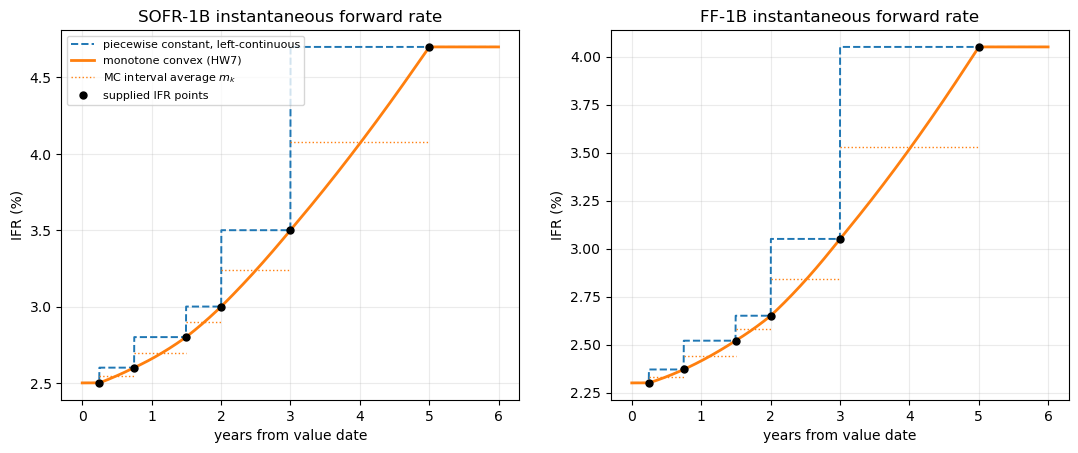

SOFR-1B
      from         to  avg IFR m_k (%)  f'' = c_k (%/yr^2)  monotone  convex
2026-04-02 2026-10-02         2.547721            0.108773      True    True
2026-10-02 2027-07-02         2.692739            0.155764      True    True
2027-07-02 2028-01-03         2.896310            0.172357      True    True
2028-01-03 2029-01-02         3.241390            0.103887      True    True
2029-01-02 2031-01-02         4.078061            0.065816      True    True
FF-1B
      from         to  avg IFR m_k (%)  f'' = c_k (%/yr^2)  monotone  convex
2026-04-02 2026-10-02         2.332957            0.097545      True    True
2026-10-02 2027-07-02         2.440648            0.093358      True    True
2027-07-02 2028-01-03         2.581988            0.140721      True    True
2028-01-03 2029-01-02         2.839297            0.129135      True    True
2029-01-02 2031-01-02         3.528001            0.065998      True    True


In [2]:
# IFR curve plot: the supplied points under both interpolation methods (SOFR and FF).
import numpy as np
import matplotlib.pyplot as plt
from fixedincomelib.date import Date, accrued

value_date = "2026-01-02"
node_times = np.array([accrued(Date(value_date), Date(d)) for d in node_dates])


def build(method):
    bms = qfCreateModelBuildMethodCollection([
        qfCreateBuildMethod(kind, {**inputs, "INTERPOLATION METHOD": method, "EXTRAPOLATION METHOD": "FLAT"})
        for kind, inputs in curve_inputs])
    return qfCreateModel(value_date, "YIELD_CURVE", data_collection, bms)


models = {m: build(m) for m in ("PIECEWISE_CONSTANT_LEFT_CONTINUOUS", "MONOTONE_CONVEX")}
labels = {"PIECEWISE_CONSTANT_LEFT_CONTINUOUS": "piecewise constant, left-continuous",
          "MONOTONE_CONVEX": "monotone convex (HW7)"}
grid = np.linspace(0.0, 6.0, 2401)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (index, quotes) in zip(axes, (("SOFR-1B", sofr_quotes), ("FF-1B", ff_quotes))):
    for method, model in models.items():
        it = model.retrieve_model_component(index).state_data_interpolator
        ax.plot(grid, 100 * np.array([it.interpolate(t) for t in grid]), label=labels[method],
                lw=2.0 if method == "MONOTONE_CONVEX" else 1.4, ls="-" if method == "MONOTONE_CONVEX" else "--")
    it = models["MONOTONE_CONVEX"].retrieve_model_component(index).state_data_interpolator
    for k in range(len(node_times) - 1):   # the average IFR the MC curve assigns to each node interval
        ax.hlines(100 * it.interval_averages[k], node_times[k], node_times[k + 1], color="tab:orange", lw=1.0, ls=":",
                  label="MC interval average $m_k$" if k == 0 else None)
    ax.plot(node_times, 100 * quotes["values"].to_numpy(), "ko", ms=5, label="supplied IFR points", zorder=5)
    ax.set_title(f"{index} instantaneous forward rate")
    ax.set_xlabel("years from value date")
    ax.set_ylabel("IFR (%)")
    ax.grid(alpha=0.25)
axes[0].legend(loc="upper left", fontsize=8)
plt.show()

# Numerical check of the two properties on every node interval (fine grid, first and second differences).
for index in ("SOFR-1B", "FF-1B"):
    it = models["MONOTONE_CONVEX"].retrieve_model_component(index).state_data_interpolator
    rows = []
    for k in range(len(node_times) - 1):
        g = np.linspace(node_times[k], node_times[k + 1], 2001)
        v = np.array([it.interpolate(t) for t in g])
        rows.append([node_dates[k], node_dates[k + 1], 100 * it.interval_averages[k], 100 * it.interval_curvatures[k],
                     bool(np.all(np.diff(v) >= -1e-16)), bool(np.all(np.diff(v, 2) >= -1e-16))])
    print(index)
    print(pd.DataFrame(rows, columns=["from", "to", "avg IFR m_k (%)", "f'' = c_k (%/yr^2)", "monotone", "convex"]).to_string(index=False))


**How the method works, and why it is monotone and convex**

The supplied values are *point* values $f_j = f(t_j)$ of the instantaneous forward rate, so the
curve has to pass through the black dots. On each node interval $[t_k, t_{k+1}]$ (length $h_k$,
local coordinate $u = (t-t_k)/h_k$) I use Hagan–West's quadratic (*Interpolation Methods for Curve
Construction*, eq. 34/47):

$$f(t) = m_k + g^0_k\,(1-4u+3u^2) + g^1_k\,(-2u+3u^2),\qquad g^0_k = f_k - m_k,\; g^1_k = f_{k+1}-m_k,$$

the unique quadratic through both node values whose **average over the interval is $m_k$** (both
basis functions integrate to zero on $[0,1]$; the dotted orange levels in the plot are the $m_k$).
Hagan–West take $m_k$ from a market discrete forward; with point data it is the one free parameter
per interval, and I set it from a local curvature estimate $c_k$:

$$m_k = \tfrac12 (f_k + f_{k+1}) - \tfrac{h_k^2}{12}\, c_k ,$$

which is exactly the average of a quadratic with second derivative $c_k$ through the two endpoints.
On the interval $f'' \equiv c_k$, so:

* **Convexity.** $c_k$ is the mean of the second derivatives of the two parabolas through
  $(t_{k-1},t_k,t_{k+1})$ and $(t_k,t_{k+1},t_{k+2})$ (one-sided at the end intervals; $0$ if they
  disagree in sign, i.e. the data inflects). For the data above every second divided difference is
  positive, so every $c_k>0$ and every piece is convex — a quadratic cannot change curvature inside an
  interval. Equivalently $m_k$ sits below the chord midpoint (Hermite–Hadamard), as the plot shows.
* **Monotonicity.** The end slopes of the piece are $f'(t_k^+) = \delta_k - h_k c_k/2$ and
  $f'(t_{k+1}^-) = \delta_k + h_k c_k/2$ with $\delta_k = (f_{k+1}-f_k)/h_k$. A quadratic is monotone on
  the interval iff these share a sign, i.e. iff $|c_k| \le 2|\delta_k|/h_k$ — Hagan–West's sector (i),
  where $g'(0)$ and $g'(1)$ agree. I **cap** $c_k$ at that bound. For the data above the cap is slack by
  a factor of 4.6 to 9.7, so the pieces are the untouched parabola averages; when the cap binds the piece
  starts (or ends) with zero slope instead of overshooting. A monotone piece is bounded by its two node
  values, so the curve never leaves the range of the data and positive data give a positive curve.
* **Continuity** holds because both pieces meeting at $t_k$ take the value $f_k$ there; outside the
  nodes the curve is FLAT ($f_0$ before the first node, $f_{n-1}$ after the last), and a one-node curve
  (the funding spread) is that constant.

**Data that cannot satisfy everything.** A local maximum at a node (hump) gives concave pieces with
zero slope at the node, never an invented extremum inside an interval; equal neighbouring values give a
flat piece; a sign change in the data's curvature gives a straight piece between the two parabolas; a
step too steep for a monotone parabola is handled by the cap. What is given up relative to
Hagan–West is their flat-segment sectors (ii)–(iv) — unnecessary once the cap guarantees sector (i) —
and relative to a spline the curve is only $C^0$ at the nodes, which Hagan–West accept in exchange for
locality (each piece depends on at most four node values). Details, proofs and tests:
`docs/hw7-implementation.md`, `tests/test_monotone_convex_interpolator.py`.


In [3]:
# 1. FRA — piecewise constant
fra_pcp_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_pcp_model = qfCreateModel(
    fra_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_pcp_product = qfCreateProductFRA(
    effective_date=fra_pcp_convention['effective date'],
    term_or_termination_date=fra_pcp_convention['termination date'],
    projection_index=fra_pcp_convention['projection index'],
    fixed_rate=fra_pcp_convention['fixed rate'],
    notional=fra_pcp_convention['notional'],
    pay_or_rec=fra_pcp_convention['pay or receive'],
    accrual_basis=fra_pcp_convention['accrual basis'],
    business_day_convention=fra_pcp_convention['business day convention'],
    holiday_convention=fra_pcp_convention['holiday convention'],
)
fra_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_pcp_convention["funding index"],
    }),
])
fra_pcp_pv = qfCreateValueReport(fra_pcp_model, fra_pcp_product, fra_pcp_parameters, "PV")[0][1]
print("FRA | PCP PV:", fra_pcp_pv)


FRA | PCP PV: 2908.2866392379638


In [4]:
# 2. FRA — your interpolator
fra_student_convention = {
    'effective date': '2026-05-05',
    'termination date': '2026-11-05',
    'projection index': 'SOFR-1B',
    'fixed rate': 0.032,
    'notional': 1000000,
    'pay or receive': 'receive',
    'accrual basis': 'ACT/360',
    'business day convention': 'F',
    'holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": fra_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": fra_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
fra_student_model = qfCreateModel(
    fra_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
fra_student_product = qfCreateProductFRA(
    effective_date=fra_student_convention['effective date'],
    term_or_termination_date=fra_student_convention['termination date'],
    projection_index=fra_student_convention['projection index'],
    fixed_rate=fra_student_convention['fixed rate'],
    notional=fra_student_convention['notional'],
    pay_or_rec=fra_student_convention['pay or receive'],
    accrual_basis=fra_student_convention['accrual basis'],
    business_day_convention=fra_student_convention['business day convention'],
    holiday_convention=fra_student_convention['holiday convention'],
)
fra_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": fra_student_convention["funding index"],
    }),
])
fra_student_pv = qfCreateValueReport(fra_student_model, fra_student_product, fra_student_parameters, "PV")[0][1]
print("FRA | Student PV:", fra_student_pv)
print("Student minus PCP:", fra_student_pv - fra_pcp_pv)


FRA | Student PV: 3262.37705890456
Student minus PCP: 354.09041966659606


**FRA: why the PV rises from 2,908.29 to 3,262.38 (+354.09).**
The FRA receives 3.2% against the SOFR forward over 2026-05-05 → 2026-11-05, which lies inside the
first node interval (Apr-2026 → Oct-2026). The left-continuous PCP curve puts the *right* node's 2.6%
on that whole interval, giving a forward of 2.6182%. The monotone convex curve rises from 2.5% at
Apr-2026 towards 2.6%, with interval average 2.5477% (below the 2.55% chord midpoint because the
curve is convex), giving a forward of 2.5476% — 7.1 bp lower. A receiver gains
$N\alpha\,\Delta F\, D \approx 10^6 \times 0.5111 \times 0.000706 \times 0.978 \approx 353$,
plus a few dollars from the slightly higher funding discount factor (lower forwards everywhere
⇒ higher $D$).


In [5]:
# 3. RFR swap — piecewise constant
swap_pcp_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_pcp_model = qfCreateModel(
    swap_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_pcp_product = qfCreateProductRFRSwap(
    effective_date=swap_pcp_convention['effective date'],
    term_or_termination_date=swap_pcp_convention['termination date'],
    on_index=swap_pcp_convention['overnight index'],
    fixed_rate=swap_pcp_convention['fixed rate'],
    notional=swap_pcp_convention['notional'],
    pay_or_rec=swap_pcp_convention['pay or receive'],
    accrual_period=swap_pcp_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_pcp_convention['floating accrual period'],
    accrual_basis=swap_pcp_convention['accrual basis'],
    compounding_method=swap_pcp_convention['compounding method'],
    spread=swap_pcp_convention['floating spread'],
    payment_off_set=swap_pcp_convention['payment offset'],
    pay_business_day_convention=swap_pcp_convention['payment business day convention'],
    pay_holiday_convention=swap_pcp_convention['payment holiday convention'],
)
swap_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_pcp_convention["funding index"],
    }),
])
swap_pcp_pv = qfCreateValueReport(swap_pcp_model, swap_pcp_product, swap_pcp_parameters, "PV")[0][1]
print("RFR swap | PCP PV:", swap_pcp_pv)


RFR swap | PCP PV: 6222.517513070154


In [6]:
# 4. RFR swap — your interpolator
swap_student_convention = {
    'effective date': '2026-04-02',
    'termination date': '2029-04-02',
    'overnight index': 'SOFR-1B',
    'fixed rate': 0.034,
    'notional': 1000000,
    'pay or receive': 'receive',
    'fixed accrual period': '1Y',
    'floating accrual period': '1Y',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'floating spread': 0.0,
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": swap_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": swap_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
swap_student_model = qfCreateModel(
    swap_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
swap_student_product = qfCreateProductRFRSwap(
    effective_date=swap_student_convention['effective date'],
    term_or_termination_date=swap_student_convention['termination date'],
    on_index=swap_student_convention['overnight index'],
    fixed_rate=swap_student_convention['fixed rate'],
    notional=swap_student_convention['notional'],
    pay_or_rec=swap_student_convention['pay or receive'],
    accrual_period=swap_student_convention['fixed accrual period'],
    floating_leg_accrual_period=swap_student_convention['floating accrual period'],
    accrual_basis=swap_student_convention['accrual basis'],
    compounding_method=swap_student_convention['compounding method'],
    spread=swap_student_convention['floating spread'],
    payment_off_set=swap_student_convention['payment offset'],
    pay_business_day_convention=swap_student_convention['payment business day convention'],
    pay_holiday_convention=swap_student_convention['payment holiday convention'],
)
swap_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": swap_student_convention["funding index"],
    }),
])
swap_student_pv = qfCreateValueReport(swap_student_model, swap_student_product, swap_student_parameters, "PV")[0][1]
print("RFR swap | Student PV:", swap_student_pv)
print("Student minus PCP:", swap_student_pv - swap_pcp_pv)


RFR swap | Student PV: 12860.399518135455
Student minus PCP: 6637.882005065301


**RFR swap: why the PV rises from 6,222.52 to 12,860.40 (+6,637.88).**
Receive fixed 3.4% vs compounded SOFR, three annual periods from Apr-2026 to Apr-2029. Each coupon's
compounded rate is $D(T_s)/D(T_e)-1$ scaled, so it equals the *average* IFR over the coupon under
either method. PCP assigns each node interval the value at its right end (2.6, 2.8, 3.0, 3.5, 4.7%);
the monotone convex curve averages 2.548, 2.693, 2.896, 3.241, 4.078% on the same intervals — always
lower for increasing data, since $m_k < \tfrac12(f_k+f_{k+1}) < f_{k+1}$. The floating leg therefore
falls from 90,552.57 to 84,253.77 (−6,298.80), while the fixed leg rises slightly, 96,775.09 →
97,114.17 (+339.09), because the funding curve (SOFR + 5 bp) discounts less. Net: +6,637.88, i.e. the
PCP reading of "2.6% from April" overstated the forwards by roughly 20 bp on average over three years.


In [7]:
# 5. Overnight basis swap — piecewise constant
basis_pcp_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'PIECEWISE_CONSTANT_LEFT_CONTINUOUS',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_pcp_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_pcp_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_pcp_model = qfCreateModel(
    basis_pcp_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_pcp_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_pcp_convention['effective date'],
    term_or_termination_date=basis_pcp_convention['termination date'],
    on_index_leg_1=basis_pcp_convention['overnight index leg 1'],
    on_index_leg_2=basis_pcp_convention['overnight index leg 2'],
    spread_over_leg_1=basis_pcp_convention['spread over leg 1'],
    notional=basis_pcp_convention['notional'],
    pay_or_rec_leg_1=basis_pcp_convention['pay or receive leg 1'],
    accrual_period_1=basis_pcp_convention['accrual period leg 1'],
    accrual_period_2=basis_pcp_convention['accrual period leg 2'],
    accrual_basis=basis_pcp_convention['accrual basis'],
    compounding_method=basis_pcp_convention['compounding method'],
    payment_off_set=basis_pcp_convention['payment offset'],
    pay_business_day_convention=basis_pcp_convention['payment business day convention'],
    pay_holiday_convention=basis_pcp_convention['payment holiday convention'],
)
basis_pcp_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_pcp_convention["funding index"],
    }),
])
basis_pcp_pv = qfCreateValueReport(basis_pcp_model, basis_pcp_product, basis_pcp_parameters, "PV")[0][1]
print("Overnight basis swap | PCP PV:", basis_pcp_pv)


Overnight basis swap | PCP PV: 8351.348908181993


In [8]:
# 6. Overnight basis swap — your interpolator
basis_student_convention = {
    'effective date': '2026-07-02',
    'termination date': '2028-07-03',
    'overnight index leg 1': 'SOFR-1B',
    'overnight index leg 2': 'FF-1B',
    'spread over leg 1': 0.001,
    'notional': 1000000,
    'pay or receive leg 1': 'receive',
    'accrual period leg 1': '3M',
    'accrual period leg 2': '3M',
    'accrual basis': 'ACT/360',
    'compounding method': 'compound',
    'payment offset': '2D',
    'payment business day convention': 'F',
    'payment holiday convention': 'USGS',
    'value date': '2026-01-02',
    'funding index': 'SOFR-1B-FLAT',
    'interpolation method': 'MONOTONE_CONVEX',
    'extrapolation method': 'FLAT',
}

build_methods = qfCreateModelBuildMethodCollection([
    qfCreateBuildMethod(kind, {
        **inputs,
        "INTERPOLATION METHOD": basis_student_convention["interpolation method"],
        "EXTRAPOLATION METHOD": basis_student_convention["extrapolation method"],
    }) for kind, inputs in curve_inputs
])
basis_student_model = qfCreateModel(
    basis_student_convention["value date"], "YIELD_CURVE", data_collection, build_methods,
)
basis_student_product = qfCreateProductOvernightIndexBasisSwap(
    effective_date=basis_student_convention['effective date'],
    term_or_termination_date=basis_student_convention['termination date'],
    on_index_leg_1=basis_student_convention['overnight index leg 1'],
    on_index_leg_2=basis_student_convention['overnight index leg 2'],
    spread_over_leg_1=basis_student_convention['spread over leg 1'],
    notional=basis_student_convention['notional'],
    pay_or_rec_leg_1=basis_student_convention['pay or receive leg 1'],
    accrual_period_1=basis_student_convention['accrual period leg 1'],
    accrual_period_2=basis_student_convention['accrual period leg 2'],
    accrual_basis=basis_student_convention['accrual basis'],
    compounding_method=basis_student_convention['compounding method'],
    payment_off_set=basis_student_convention['payment offset'],
    pay_business_day_convention=basis_student_convention['payment business day convention'],
    pay_holiday_convention=basis_student_convention['payment holiday convention'],
)
basis_student_parameters = qfCreateValuationParametersCollection([
    qfCreateValuationParameters("FUNDING INDEX PARAMETER", {
        "FUNDING INDEX": basis_student_convention["funding index"],
    }),
])
basis_student_pv = qfCreateValueReport(basis_student_model, basis_student_product, basis_student_parameters, "PV")[0][1]
print("Overnight basis swap | Student PV:", basis_student_pv)
print("Student minus PCP:", basis_student_pv - basis_pcp_pv)


Overnight basis swap | Student PV: 7624.099110655072
Student minus PCP: -727.2497975269216


**Overnight basis swap: why the PV falls from 8,351.35 to 7,624.10 (−727.25).**
Receive SOFR + 10 bp, pay FF, quarterly from Jul-2026 to Jul-2028. Both projected legs fall under
the monotone convex curve, because both data sets are increasing and so both sets of interval averages
lie below the PCP right-node rates: the SOFR leg (ex spread) 57,542.73 → 54,478.37 (−3,064.37) and
the FF leg 51,134.04 → 48,799.89 (−2,334.16). The received SOFR leg falls by more because the SOFR
curve is steeper (2.5 → 4.7% against 2.3 → 4.05%), so its interval averages sit further below the
right-node values. The spread stream is unaffected by projection and changes only through discounting
(1,942.66 → 1,945.62). Net: −3,064.37 + 2.96 + 2,334.16 = −727.25.
